In [5]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

cwd = Path.cwd().resolve()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / 'scripts').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Root repo:', ROOT)


Root repo: C:\Users\Kiranna\OneDrive\Documents\VS Code\Structural Damage Classification


In [6]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency

from scripts.preprocess import load_data

# Read Data

In [7]:
train = load_data('train.csv')
test = load_data('test.csv')
sample_submission = load_data('sample_submission.csv')

In [8]:
print('Train shape :', train.shape)
print('Test shape  :', test.shape)
print('Sample submission shape:', sample_submission.shape)

Train shape : (533465, 17)
Test shape  : (228629, 16)
Sample submission shape: (228629, 2)


In [9]:
train.head()

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


In [10]:
test.head()

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,superstructure
0,122207000141,12,1205,120504,1,8,240,10,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,Rectangular,has_superstructure_mud_mortar_stone
1,284909000871,28,2810,281006,3,4,384,22,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
2,241904000231,24,2409,240909,2,999,384,21,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
3,248308000891,24,2412,241202,2,16,527,19,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
4,300405002981,30,3001,300104,2,6,280,16,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Not attached,Rectangular,has_superstructure_mud_mortar_stone


In [11]:
sample_submission.head()

,building_id,damage_grade
0,122207000141,Grade 3
1,284909000871,Grade 1
2,241904000231,Grade 5
3,248308000891,Grade 4
4,300405002981,Grade 2


In [12]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

# Cek Missing Values

In [13]:
missing_train = train.isna().sum()
missing_test = test.isna().sum()
print('Missing values - train:\n', missing_train)
print('Missing values - test:\n', missing_test)

Missing values - train:
 building_id               0
district_id               0
vdcmun_id                 0
ward_id                   0
count_floors_pre_eq       0
age_building              0
plinth_area_sq_ft         0
height_ft_pre_eq          0
land_surface_condition    0
foundation_type           0
roof_type                 0
ground_floor_type         0
other_floor_type          0
position                  0
plan_configuration        0
damage_grade              0
superstructure            0
dtype: int64
Missing values - test:
 building_id               0
district_id               0
vdcmun_id                 0
ward_id                   0
count_floors_pre_eq       0
age_building              0
plinth_area_sq_ft         0
height_ft_pre_eq          0
land_surface_condition    0
foundation_type           0
roof_type                 0
ground_floor_type         0
other_floor_type          0
position                  0
plan_configuration        0
superstructure            0
dtype: int64


# Cek Duplikat

In [14]:
print('Jumlah duplikat baris di train:', train.duplicated().sum())
print('Jumlah duplikat baris di test:', test.duplicated().sum())

Jumlah duplikat baris di train: 0
Jumlah duplikat baris di test: 0


Tidak ada missing value dan tidak ada baris duplikat, baik di train maupun test.

# Statistika Deskriptif

In [15]:
numeric_cols = ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']
train[numeric_cols].describe()

,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq
count,533465.000000,533465.000000,533465.000000,533465.000000
mean,2.088000,24.337319,406.523453,16.047675
std,0.655001,64.999055,226.610477,5.490926
min,1.000000,0.000000,70.000000,6.000000
25%,2.000000,9.000000,280.000000,12.000000
50%,2.000000,16.000000,358.000000,16.000000
75%,2.000000,27.000000,470.000000,18.000000
max,9.000000,999.000000,5000.000000,99.000000


# Cek Outlier dengan Boxplot

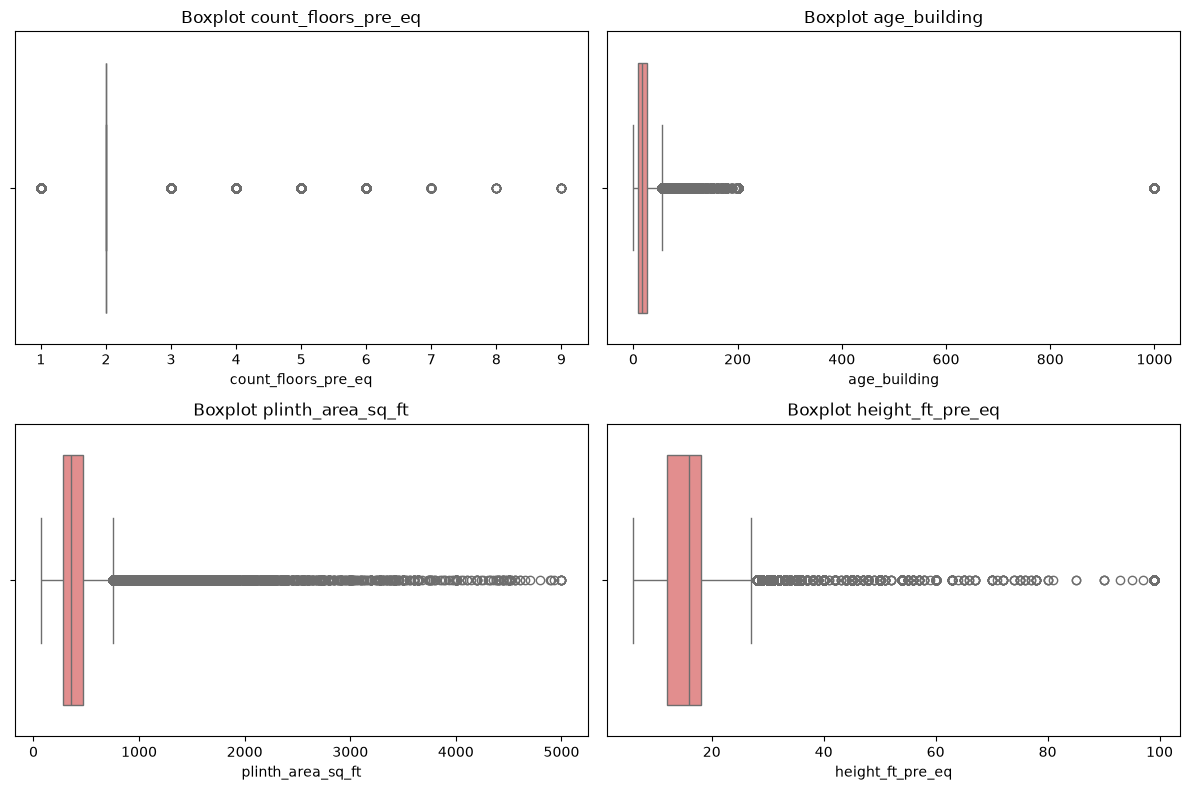

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    data_to_plot = train[[col]].copy()
    sns.boxplot(x=data_to_plot[col], ax=ax, color='lightcoral')
    ax.set_title(f'Boxplot {col}')

plt.tight_layout()
plt.show()


1. count_floors_pre_eq: Mayoritas bangunan punya 2 lantai sehingga titik-titik di 1 dan 3-9 terdeteksi sebagai outlier. Namun, di realita, lantai 1, 3-9 masih lumrah
2. age_building: Median sekitar 15-20 tahun, tapi ada yang sampai 200 tahun dengan beberapa titik outlier, kemungkinan usia bangunan tua yang memang valid (bangunan heritage). Namun ada yang nilainya 999 yang tidak mungkin sehingga akan di treatment
3. plinth_area_sq_ft: median rendah (~300-500), tapi ekor kanan sangat panjang sampai 5000, dengan ribuan titik outlier. Luas bangunan memang bisa bervariasi jauh
4. height_ft_pre_eq: median sekitar 15, ekor kanan sampai 100. Kemungkinan besar berkorelasi kuat dengan count_floors_pre_eq (makin banyak lantai, makin tinggi), jadi outlier di sini kemungkinan konsisten dengan bangunan tinggi lantai banyak, bukan data error.

# Korelasi antar Fitur Numerik

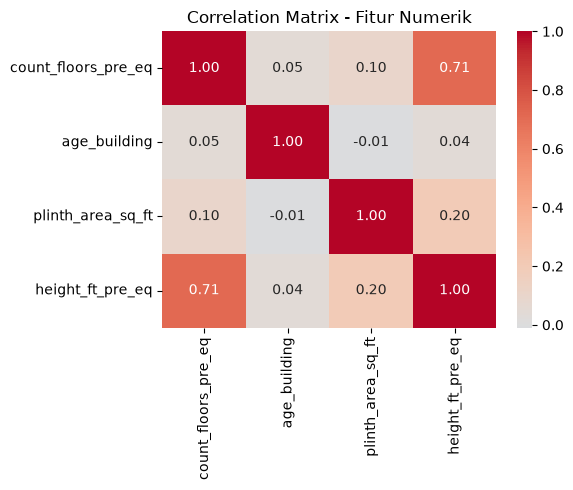

In [17]:
corr = train[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Matrix - Fitur Numerik')
plt.tight_layout()
plt.show()

- Hubungan terkuat adalah `height_ft_pre_eq` dengan `count_floors_pre_eq` (r = 0,71), lalu `plinth_area_sq_ft` dengan `height_ft_pre_eq` (r = 0,20). Pasangan lainnya mendekati 0.
- Korelasi `age_building` kemungkinan terdistorsi oleh nilai 999.
- Korelasi tinggi antara tinggi dan jumlah lantai (0,71) perlu diwaspadai (multikolinearitas)

### Mengecek jumlah dan proporsi nilai 999 pada age_building

In [18]:
(train['age_building'] == 999).sum()

np.int64(2198)

In [19]:
(test['age_building'] == 999).sum()

np.int64(946)

In [20]:
(train['age_building'] == 999).mean() * 100

np.float64(0.4120232817523174)

In [21]:
(test['age_building'] == 999).mean() * 100

np.float64(0.4137707814844136)

# Distribusi Target

               count  percentage (%)
damage_grade                        
Grade 1        55170           10.34
Grade 2        61080           11.45
Grade 3        95488           17.90
Grade 4       128691           24.12
Grade 5       193036           36.19


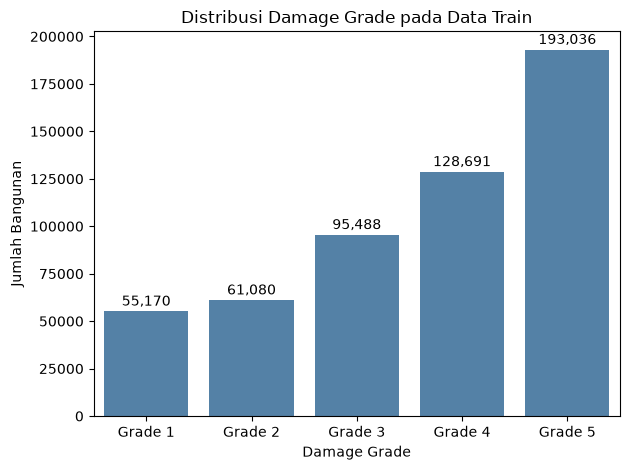

In [22]:
target_col = 'damage_grade'
id_col = 'building_id'

grade_order = ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5']

target_counts = train[target_col].value_counts().reindex(grade_order)
target_pct = (target_counts / target_counts.sum() * 100).round(2)

print(pd.DataFrame({'count': target_counts, 'percentage (%)': target_pct}))

fig, ax = plt.subplots()
sns.barplot(x=target_counts.index, y=target_counts.values, order=grade_order, ax=ax, color='steelblue')
ax.set_title('Distribusi Damage Grade pada Data Train')
ax.set_xlabel('Damage Grade')
ax.set_ylabel('Jumlah Bangunan')
for i, v in enumerate(target_counts.values):
    ax.text(i, v + 3000, f'{v:,}', ha='center')
plt.tight_layout()
plt.show()


Distribusi antar kelas timpang sehingga perlu penyesuaian saat modelling

# Fitur Kategorikal

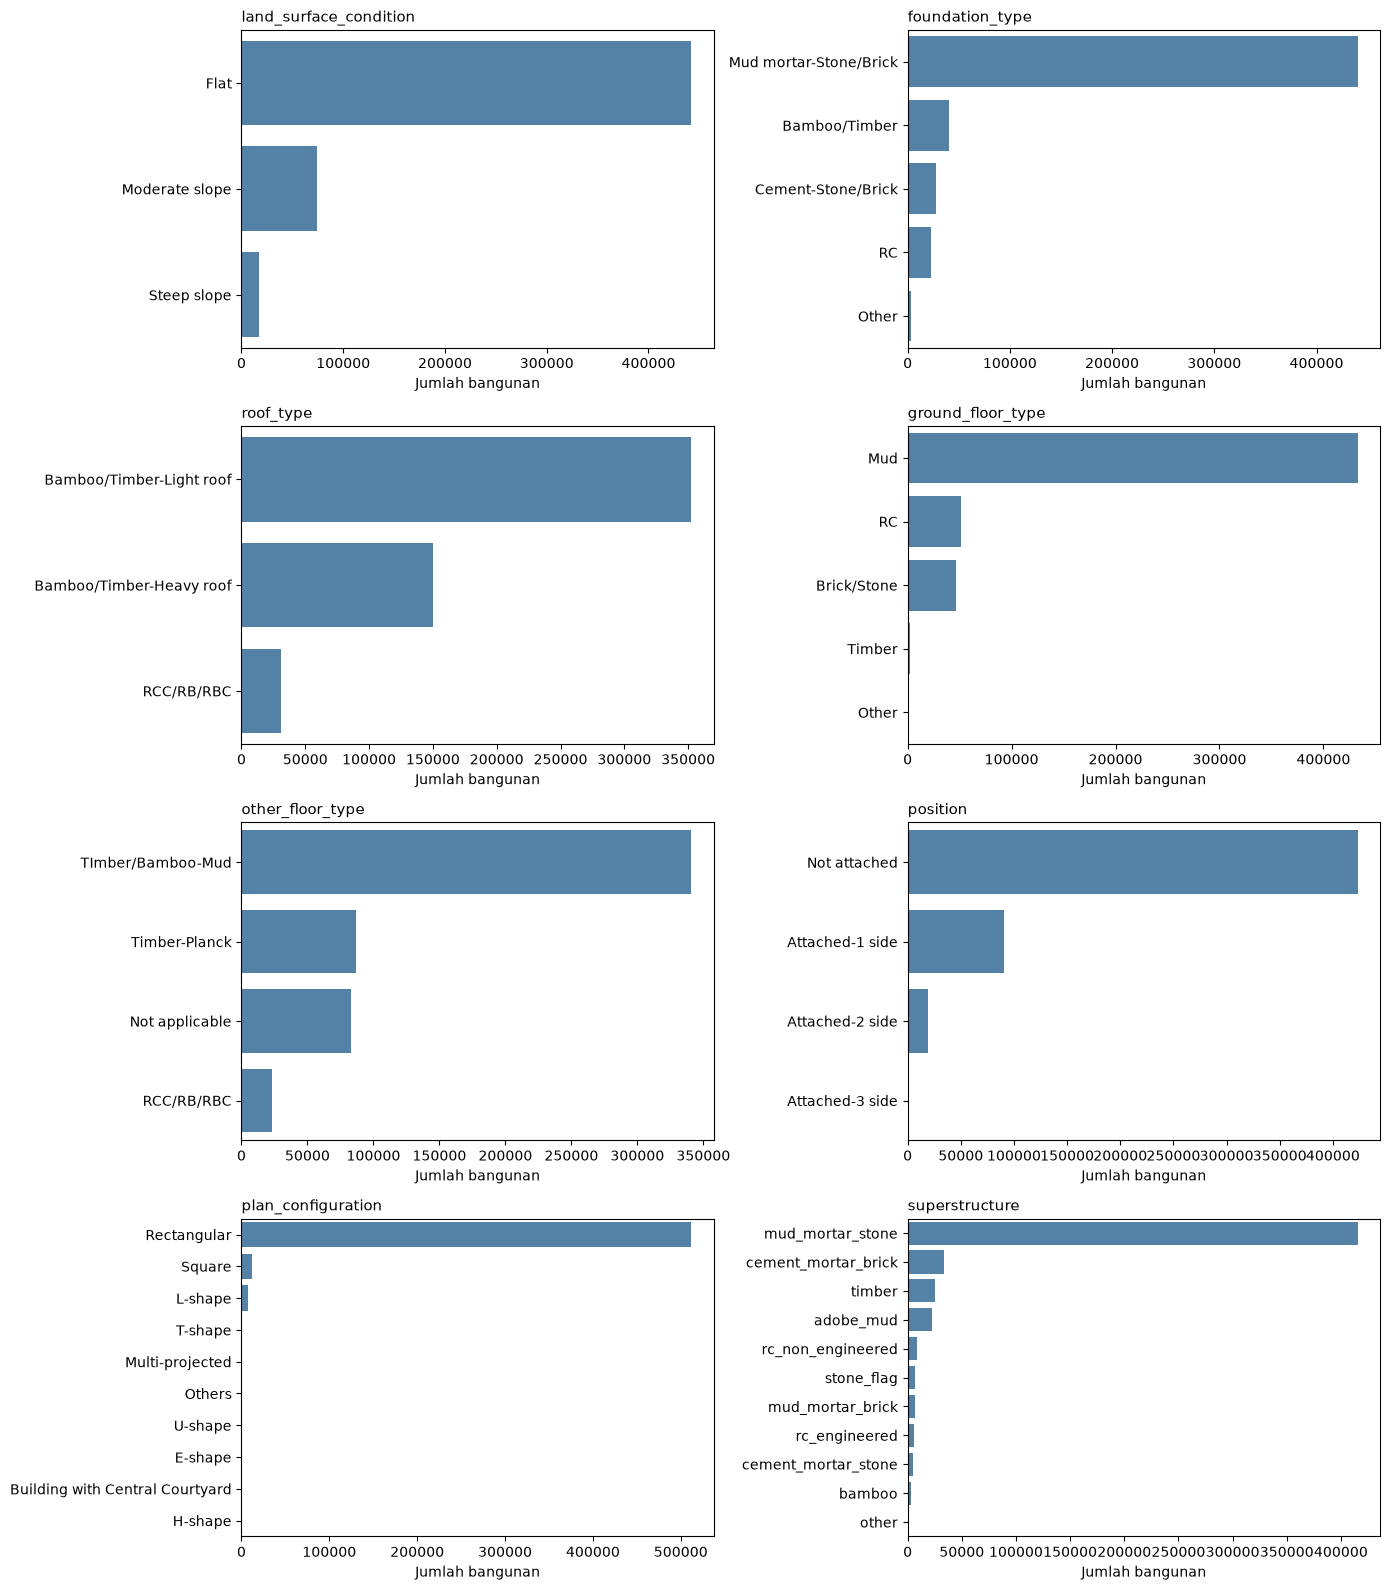

In [23]:
categorical_cols = [
    'land_surface_condition',
    'foundation_type',
    'roof_type',
    'ground_floor_type',
    'other_floor_type',
    'position',
    'plan_configuration',
    'superstructure'
]
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, col in zip(axes.flatten(), categorical_cols):
    order = train[col].value_counts().index
    sns.countplot(data=train, y=col, order=order, ax=ax, color='steelblue')
    ax.set_title(col, loc='left', fontsize=11)
    ax.set_xlabel('Jumlah bangunan')
    ax.set_ylabel('')
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([str(label).replace('has_superstructure_', '') for label in order])

plt.tight_layout()
plt.show()

- Distribusi sangat timpang (skewed) di hampir semua kategori; land_surface_condition didominasi "Flat", foundation_type oleh "Mud mortar-Stone/Brick", dan plan_configuration oleh "Rectangular". Kategori minoritas (seperti "Steep slope", "RC", atau bentuk "L/T/U-shape") memiliki proporsi sangat kecil.
- Material konstruksi secara konsisten mengarah pada bangunan tradisional/rentan: ground_floor_type didominasi "Mud" (lantai tanah), roof_type oleh "Bamboo/Timber-Light roof", dan superstructure oleh "mud_mortar_stone".
- Mayoritas bangunan bersifat mandiri (position: "Not attached") dan berada di lahan datar, yang mengindikasikan pola permukiman rural/tersebar.
- Dominasi material alami (tanah, batu, bambu) pada fondasi, dinding, atap, dan lantai mengindikasikan kerentanan struktural yang tinggi terhadap bencana.
- Imbalanced Classes: Distribusi yang sangat tidak seimbang akan membuat model machine learning bias terhadap kelas mayoritas sehingga perlu penanganan

# Hubungan Fitur Kategorikal dengan Target
Untuk tiap kategori dihitung proporsi bangunan di setiap `damage_grade`. Batang diurutkan dari kategori yang paling ringan kerusakannya (atas) ke yang paling parah (bawah), dan jumlah bangunan (`n`) dicantumkan karena kategori kecil mudah menyesatkan.

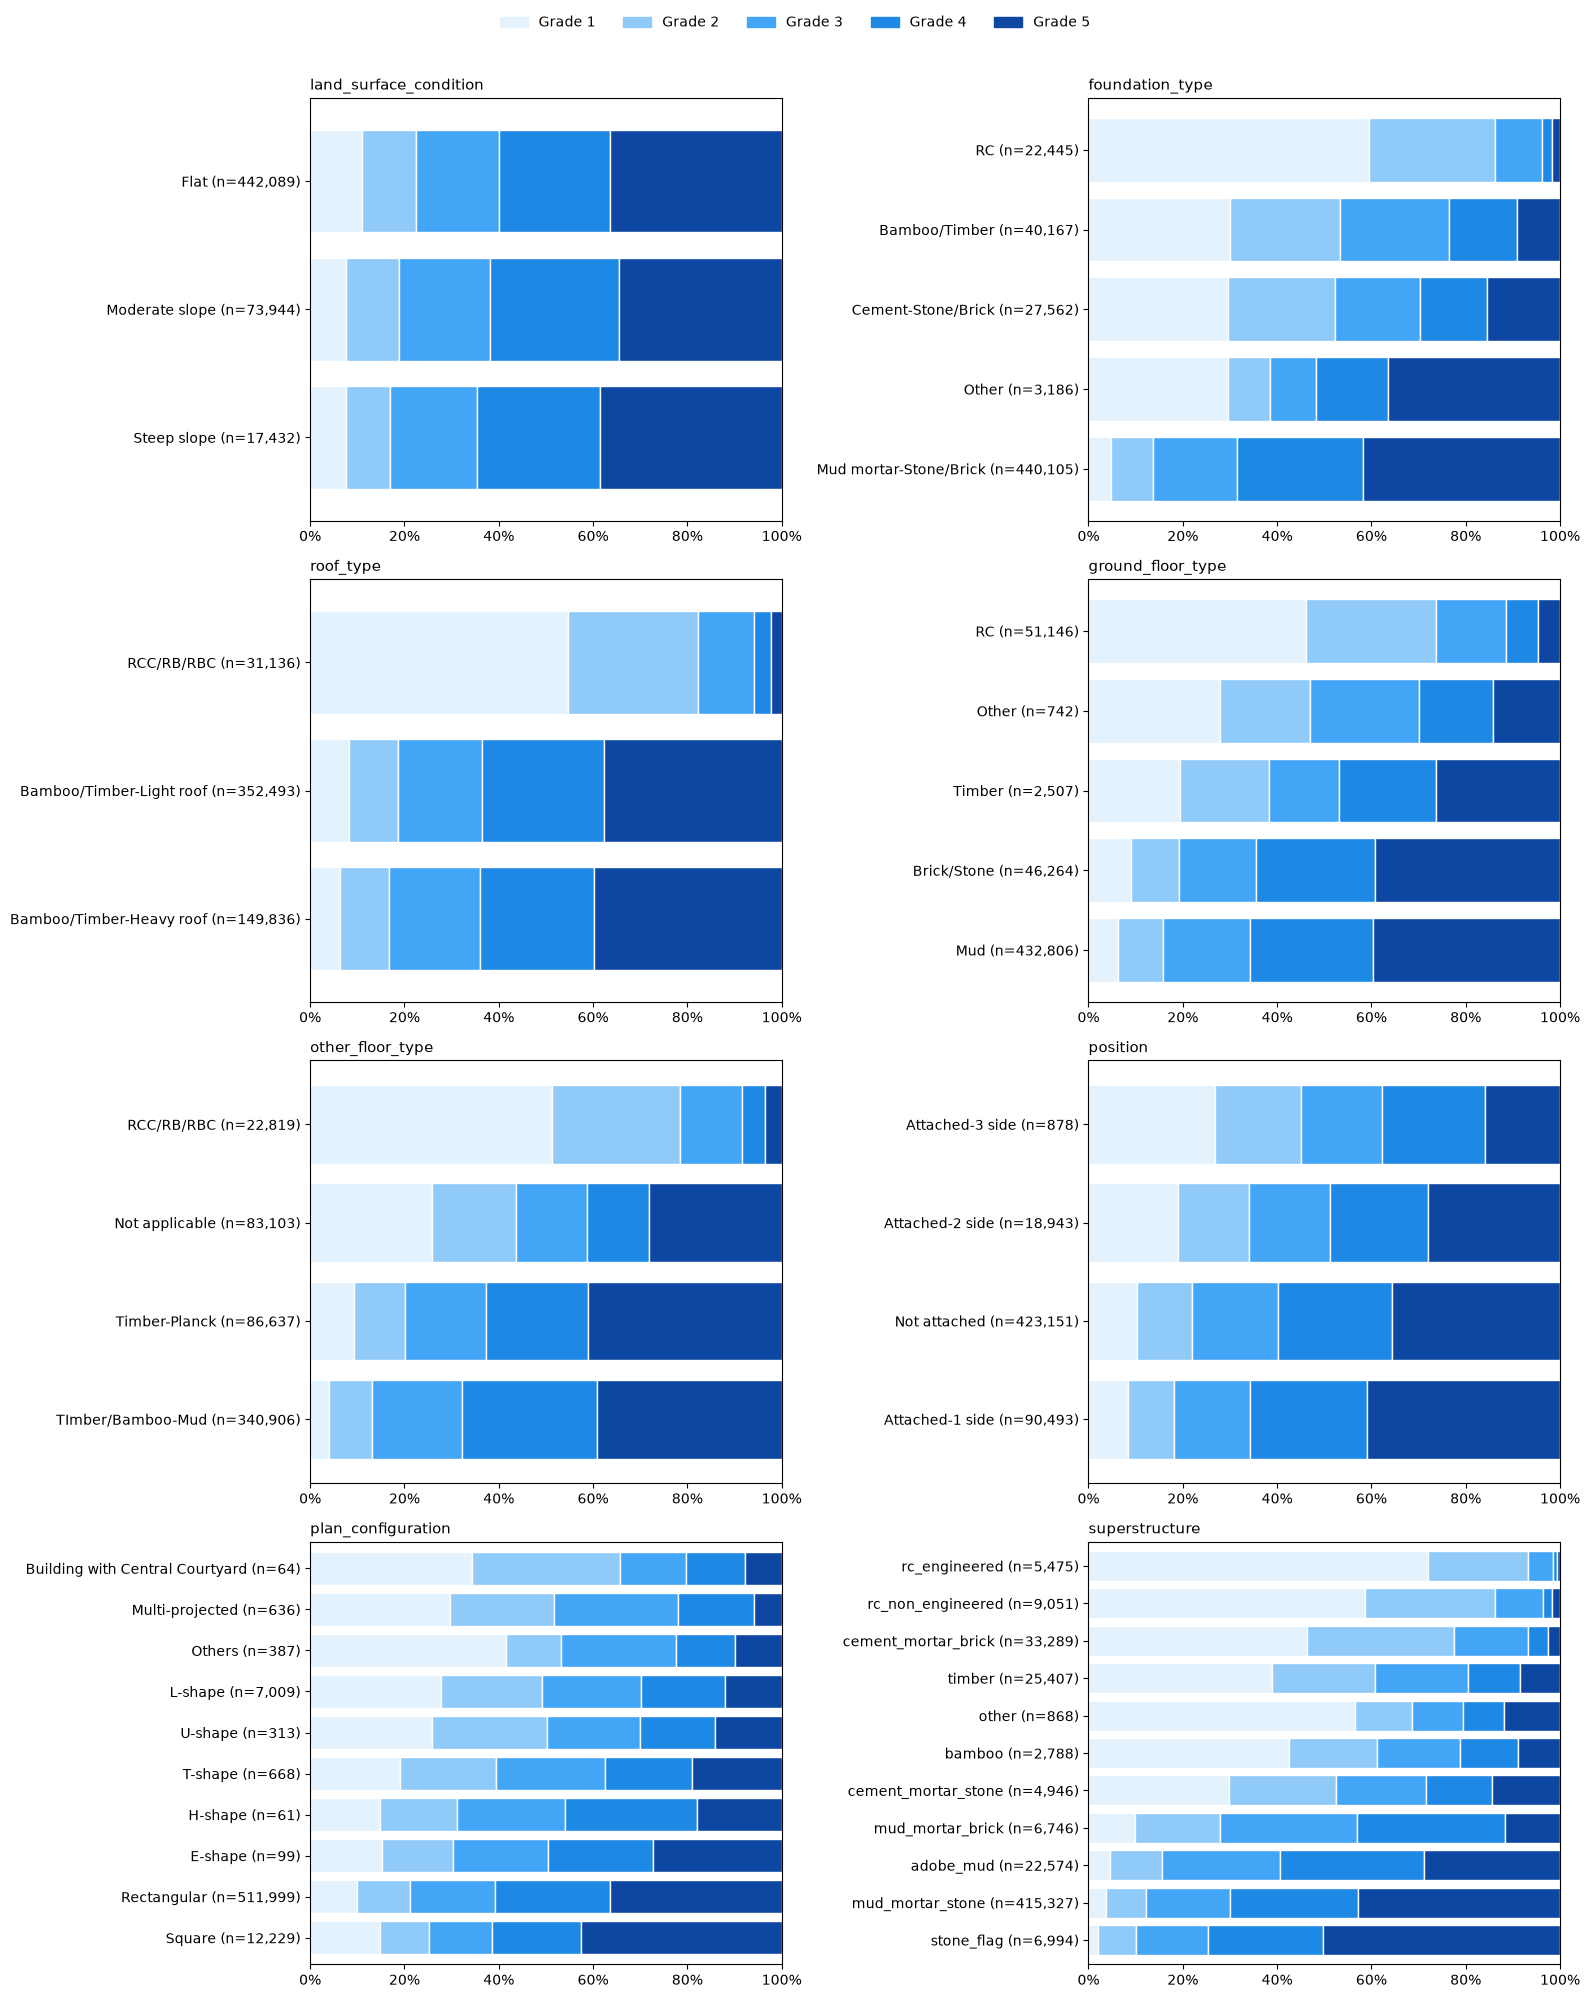

In [24]:
GRADE_COLORS = ['#e3f2fd', '#90caf9', '#42a5f5', '#1e88e5', '#0d47a1']
fig, axes = plt.subplots(4, 2, figsize=(16, 20))

for ax, col in zip(axes.flatten(), categorical_cols):
    ct = pd.crosstab(train[col], train[target_col], normalize='index')[grade_order]
    ct = ct.loc[(ct['Grade 4'] + ct['Grade 5']).sort_values().index]     # ringan -> parah
    counts = train[col].value_counts()

    ct.plot(kind='barh', stacked=True, ax=ax, color=GRADE_COLORS, width=0.8,
            edgecolor='white', linewidth=1, legend=False)
    ax.set_yticks(range(len(ct)))
    ax.set_yticklabels([f"{str(label).replace('has_superstructure_', '')} (n={counts[label]:,})" for label in ct.index])
    ax.invert_yaxis()                      # kategori paling ringan di atas
    ax.set_title(col, loc='left', fontsize=11)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel('')
    ax.set_ylabel('')

fig.legend([Patch(color=c) for c in GRADE_COLORS], grade_order, ncol=5, loc='upper center',
           bbox_to_anchor=(0.5, 1.0), frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Cramér's V** (0 = tidak ada hubungan, 1 = hubungan sempurna) antara tiap fitur kategorikal/lokasi dan `damage_grade`.

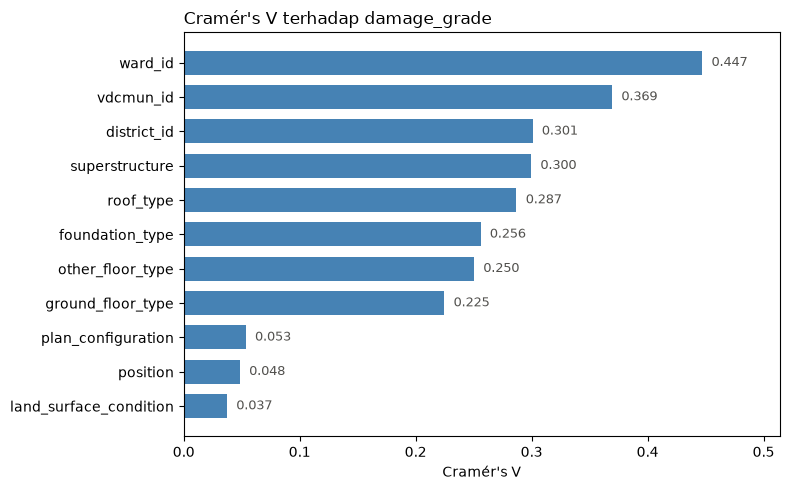

,cramers_v,jumlah_kategori
ward_id,0.447,945
vdcmun_id,0.369,110
district_id,0.301,11
superstructure,0.300,11
roof_type,0.287,3
foundation_type,0.256,5
other_floor_type,0.250,4
ground_floor_type,0.225,5
plan_configuration,0.053,10
position,0.048,4


In [25]:
def cramers_v(x, y):
    """Cramer's V dengan koreksi bias: 0 = tidak ada hubungan, 1 = hubungan sempurna."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    r, k = table.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))

location_cols = ['district_id', 'vdcmun_id', 'ward_id']

assoc = pd.Series(
    {col: cramers_v(train[col].astype(str), train[target_col]) for col in categorical_cols + location_cols}
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
plot_data = assoc.sort_values()
ax.barh(plot_data.index, plot_data.values, color='steelblue', height=0.7)
for y_pos, value in enumerate(plot_data.values):
    ax.text(value + 0.008, y_pos, f'{value:.3f}', va='center', fontsize=9, color='#52514e')
ax.set_title("Cramér's V terhadap damage_grade", loc='left')
ax.set_xlabel("Cramér's V")
ax.set_xlim(0, assoc.max() * 1.15)
plt.tight_layout()
plt.show()

assoc.round(3).to_frame("cramers_v").assign(jumlah_kategori=[train[c].nunique() for c in assoc.index])

- Material bangunan adalah pembeda terkuat. Bangunan dengan material beton bertulang (pondasi, lantai dasar, atap, dan struktur utama) didominasi Grade 1–2. Bangunan bermaterial lumpur-mortar, batu, atau kayu/bambu didominasi Grade 4–5. Jadi ketahanan terhadap gempa sangat bergantung pada jenis konstruksi.
- Pada atap, yang membedakan adalah ada tidaknya beton, bukan berat ringannya. Atap beton jauh lebih aman. Atap ringan dan atap berat terlihat hampir sama buruknya.
- Fitur material saling terkait. Pondasi, lantai, dan struktur utama pada dasarnya menggambarkan satu hal yang sama, yaitu tipe konstruksi. Untuk Random Forest ini tidak bermasalah, tapi di feature importance kontribusinya bisa terbagi di antara fitur-fitur itu.
- Beberapa fitur hampir tidak berhubungan dengan target. plan_configuration, position, dan land_surface_condition punya Cramér’s V paling kecil, dan stacked bar-nya hampir seragam antar kategori. Kemiringan tanah hanya memberi pengaruh kecil, dan position tidak membentuk pola yang rapi.
- Lokasi adalah sinyal paling kuat. Cramér’s V untuk ward_id, vdcmun_id, dan district_id lebih tinggi daripada semua fitur struktur, dan tingkat kerusakan terlihat sangat berbeda antar wilayah. Ini masuk akal karena lokasi mewakili kedekatan dengan pusat gempa dan intensitas guncangan, hal yang tidak ditangkap fitur bangunan. 

# Analisis Lokasi (`district_id`, `vdcmun_id`, `ward_id`)

In [26]:
print('Jumlah district_id :', train['district_id'].nunique())
print('Jumlah vdcmun_id   :', train['vdcmun_id'].nunique())
print('Jumlah ward_id     :', train['ward_id'].nunique())
print()
print('Setiap ward berada di tepat 1 vdcmun    :', bool((train.groupby('ward_id')['vdcmun_id'].nunique() == 1).all()))
print('Setiap vdcmun berada di tepat 1 district:', bool((train.groupby('vdcmun_id')['district_id'].nunique() == 1).all()))
print()
print('Jumlah bangunan per ward:')
print(train['ward_id'].value_counts().describe().round(0).to_string())

Jumlah district_id : 11
Jumlah vdcmun_id   : 110
Jumlah ward_id     : 945

Setiap ward berada di tepat 1 vdcmun    : True
Setiap vdcmun berada di tepat 1 district: True

Jumlah bangunan per ward:
count     945.0
mean      565.0
std       218.0
min       108.0
25%       419.0
50%       541.0
75%       679.0
max      1803.0


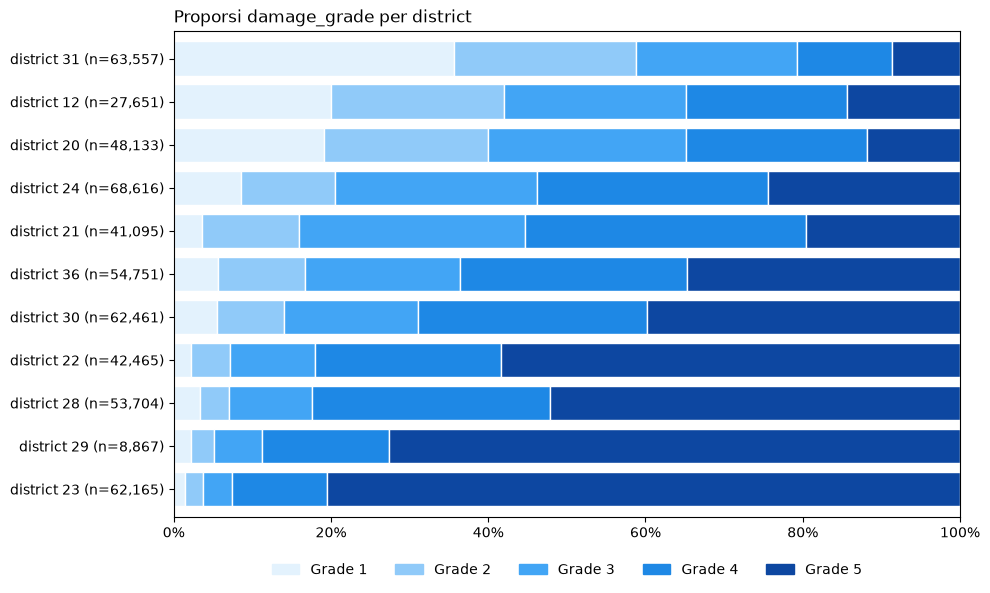

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))

ct = pd.crosstab(train['district_id'], train[target_col], normalize='index')[grade_order]
ct = ct.loc[(ct['Grade 4'] + ct['Grade 5']).sort_values().index]
counts = train['district_id'].value_counts()

ct.plot(kind='barh', stacked=True, ax=ax, color=GRADE_COLORS, width=0.8,
        edgecolor='white', linewidth=1, legend=False)
ax.set_yticks(range(len(ct)))
ax.set_yticklabels([f'district {label} (n={counts[label]:,})' for label in ct.index])
ax.invert_yaxis()                          # district paling ringan di atas
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel('')
ax.set_title('Proporsi damage_grade per district', loc='left')
ax.legend([Patch(color=c) for c in GRADE_COLORS], grade_order, ncol=5, loc='lower center',
          bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.tight_layout()
plt.show()

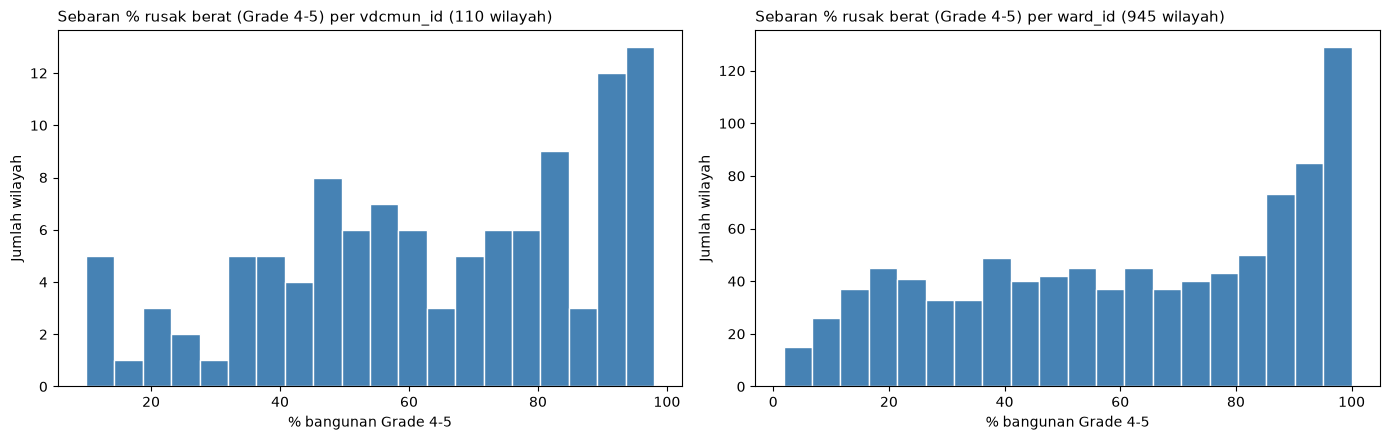

,vdcmun_id,ward_id
count,110.0,945.0
mean,63.7,61.0
std,24.8,29.0
min,9.9,1.8
25%,46.3,36.8
50%,65.4,63.7
75%,84.6,88.4
max,98.0,100.0


In [28]:
severe = train[target_col].isin(['Grade 4', 'Grade 5'])
pct_vdcmun = severe.groupby(train['vdcmun_id']).mean() * 100
pct_ward = severe.groupby(train['ward_id']).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, s, name in zip(axes, [pct_vdcmun, pct_ward], ['vdcmun_id (110 wilayah)', 'ward_id (945 wilayah)']):
    ax.hist(s, bins=20, color='steelblue', edgecolor='white', linewidth=1)
    ax.set_title(f'Sebaran % rusak berat (Grade 4-5) per {name}', loc='left', fontsize=11)
    ax.set_xlabel('% bangunan Grade 4-5')
    ax.set_ylabel('Jumlah wilayah')
plt.tight_layout()
plt.show()

pd.DataFrame({'vdcmun_id': pct_vdcmun.describe(), 'ward_id': pct_ward.describe()}).round(1)

- Tingkat kerusakan sangat berbeda antar wilayah. Antar district_id ada yang kerusakan beratnya jelas rendah dan ada yang sangat tinggi. Variasinya tetap besar saat turun ke vdcmun_id dan ward_id. Wilayah yang relatif aman dan wilayah yang parah ada berdampingan, jadi ward_id masih membawa informasi tambahan di luar district_id.
- Hierarkinya konsisten. Setiap ward berada di satu vdcmun dan setiap vdcmun di satu district. Jadi tiga kolom ini adalah resolusi lokasi yang makin halus, bukan tiga informasi yang terpisah.
- Ward cukup besar untuk dipelajari. Tidak ada ward yang hanya berisi segelintir bangunan, jadi rata-rata kerusakan per ward cukup stabil. Pola antar ward bukan sekadar kebetulan dari sampel kecil.
- Implikasi encoding: one-hot ward_id akan menambah ratusan kolo jadi akan lebih ringkas bila mengganti lokasi dengan kecenderungan kerusakan di wilayah itu (target encoding, dihitung hanya dari data latih), yang memakai informasi yang sama.

# Konsistensi Train vs Test
Model bisa memprediksi dengan baik kalau `test.csv` berasal dari distribusi yang mirip dengan `train.csv`, dan tidak berisi kategori yang belum pernah dilihat saat training.

In [29]:
rows = []
for col in categorical_cols + location_cols:
    train_set, test_set = set(train[col].unique()), set(test[col].unique())
    shares = pd.concat([train[col].value_counts(normalize=True), test[col].value_counts(normalize=True)],
                       axis=1, keys=['train', 'test']).fillna(0)
    rows.append({
        'fitur': col,
        'kategori_baru_di_test': len(test_set - train_set),
        'kategori_tidak_muncul_di_test': len(train_set - test_set),
        'selisih_proporsi_maks (poin %)': round((shares['train'] - shares['test']).abs().max() * 100, 2),
    })
pd.DataFrame(rows)

,fitur,kategori_baru_di_test,kategori_tidak_muncul_di_test,selisih_proporsi_maks (poin %)
0,land_surface_condition,0,0,0.05
1,foundation_type,0,0,0.06
2,roof_type,0,0,0.12
3,ground_floor_type,0,0,0.04
4,other_floor_type,0,0,0.06
5,position,0,0,0.07
6,plan_configuration,0,0,0.08
7,superstructure,0,0,0.06
8,district_id,0,0,0.19
9,vdcmun_id,0,0,0.08


In [30]:
pd.concat([train[numeric_cols].median(), test[numeric_cols].median(),
           train[numeric_cols].mean().round(2), test[numeric_cols].mean().round(2)],
          axis=1, keys=['median train', 'median test', 'mean train', 'mean test'])

,median train,median test,mean train,mean test
count_floors_pre_eq,2.0,2.0,2.09,2.09
age_building,16.0,16.0,24.34,24.30
plinth_area_sq_ft,358.0,360.0,406.52,407.02
height_ft_pre_eq,16.0,16.0,16.05,16.05



1. Tidak ada kategori baru di `test.csv` pada seluruh 11 fitur kategorikal dan lokasi, jadi encoder tidak akan menemui nilai yang asing saat prediksi. Tetap pakai `handle_unknown` yang aman di pipeline sebagai pengaman.
2. Proporsi tiap kategori hampir identik antara train dan test (selisih terbesar kurang dari 0,2 poin persen). Median fitur numerik sama atau nyaris sama (misalnya `plinth_area_sq_ft` 358 vs 360), dan rata-ratanya mirip

# Ringkasan Insight EDA

## Kualitas data
- Train 533.465 baris dan 17 kolom, test 228.629 baris dan 16 kolom (selisihnya kolom target `damage_grade`). Tidak ada missing value dan tidak ada baris duplikat.
- `age_building` berisi placeholder **999** ("usia tidak diketahui") di 2.198 baris train dan 946 baris test (0,41% di keduanya). Nilai ini merusak statistik: tanpa 999, rata-rata usia 20,3 tahun, dengan 999 menjadi 24,3 tahun.
- Tidak ada kategori baru di test dan distribusi train-test nyaris identik (tidak ada data drift).

## Target (`damage_grade`)
- Tidak seimbang: Grade 5 36,2%, Grade 4 24,1%, Grade 3 17,9%, Grade 2 11,4%, Grade 1 10,3% (kelas terbesar sekitar 3,5 kali kelas terkecil). Perlu `stratify` saat split dan metrik macro F1 selain accuracy.

## Fitur numerik
- `plinth_area_sq_ft`, `height_ft_pre_eq`, dan `age_building` berekor kanan panjang, tetapi nilainya wajar secara fisik, jadi tidak dihapus.
- Korelasi tinggi hanya antara `height_ft_pre_eq` dan `count_floors_pre_eq` (0,71). Korelasi `age_building` ikut tersamarkan oleh nilai 999 (0,05 dengan 999, 0,17 tanpa 999).
- Hubungan dengan target lemah (Spearman di bawah 0,25), yang paling kuat `age_building` (0,24).

## Fitur kategorikal dan lokasi
- Pembeda terkuat: **lokasi** (`ward_id`, `vdcmun_id`, `district_id`) dan **material struktur** (`superstructure`, `roof_type`, `foundation_type`, `other_floor_type`, `ground_floor_type`). Bangunan beton (RC) hanya 1-12% yang rusak berat, sedangkan bangunan lumpur-batu 65-75%.
- Hampir tidak informatif: `plan_configuration`, `position`, `land_surface_condition` (Cramér's V di bawah 0,06).
- Kerusakan sangat bervariasi antar wilayah (district 20,8% sampai 92,6% Grade 4-5).

## Implikasi untuk tahap modeling
1. Ubah `age_building == 999` menjadi `NaN`, lalu imputasi dengan median dari data train.
2. Outlier numerik tidak dihapus karena valid secara fisik dan model berbasis pohon tidak sensitif.
3. Fitur lokasi berkardinalitas tinggi (terutama `ward_id`, 945 nilai) di-target encoding, bukan one-hot. Fitur struktur bangunan memakai `OrdinalEncoder` untuk model berbasis pohon.
4. Split stratified dan metrik macro F1.
5. `building_id` hanya identifier sehingga tidak dipakai fitur.
6. Fitur dengan hubungan sangat lemah (`plan_configuration`, `position`, `land_surface_condition`) boleh dipertahankan karena Random Forest tidak terganggu oleh fitur lemah